In [191]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns

In [192]:
gsw_data = pd.read_csv('GSW_YearlyHistory_nodata_60deltas.csv')

In [193]:
years = list(range(1984, 2022))

In [207]:
def parse_water_data(gsw_data, column_name):
    years = list(range(1984, 2022))
    df = pd.DataFrame(index=years)
    
    for idx, row in gsw_data.iterrows():
        delta_name = row['Name']
        data_array = ast.literal_eval(row[column_name])
        df[delta_name] = data_array
    
    return df

notwater_df = parse_water_data(gsw_data, 'notwater')
seasonal_water_df = parse_water_data(gsw_data, 'seasonal_water')
water_df = parse_water_data(gsw_data, 'water')
nodata_df = parse_water_data(gsw_data, 'nodata')

# Also get delta areas
delta_areas = gsw_data.set_index('Name')['Shape_Area']

classified_area_df = (notwater_df + seasonal_water_df + water_df + nodata_df) # Convert to km²

# Convert nodata to fraction of delta area
nodata_fraction_df = nodata_df.copy()
for delta_name in nodata_df.columns:
    nodata_fraction_df[delta_name] = nodata_df[delta_name] / classified_area_df[delta_name]

In [208]:
# Create total water dataframe
total_land_df = seasonal_water_df + notwater_df

# Save dataframes to CSV
notwater_df.to_csv('notwater_timeseries.csv')
seasonal_water_df.to_csv('seasonal_water_timeseries.csv')
water_df.to_csv('water_timeseries.csv')
total_land_df.to_csv('total_land_timeseries.csv')
# Save nodata as fraction
nodata_fraction_df.to_csv('nodata_fraction_timeseries.csv')

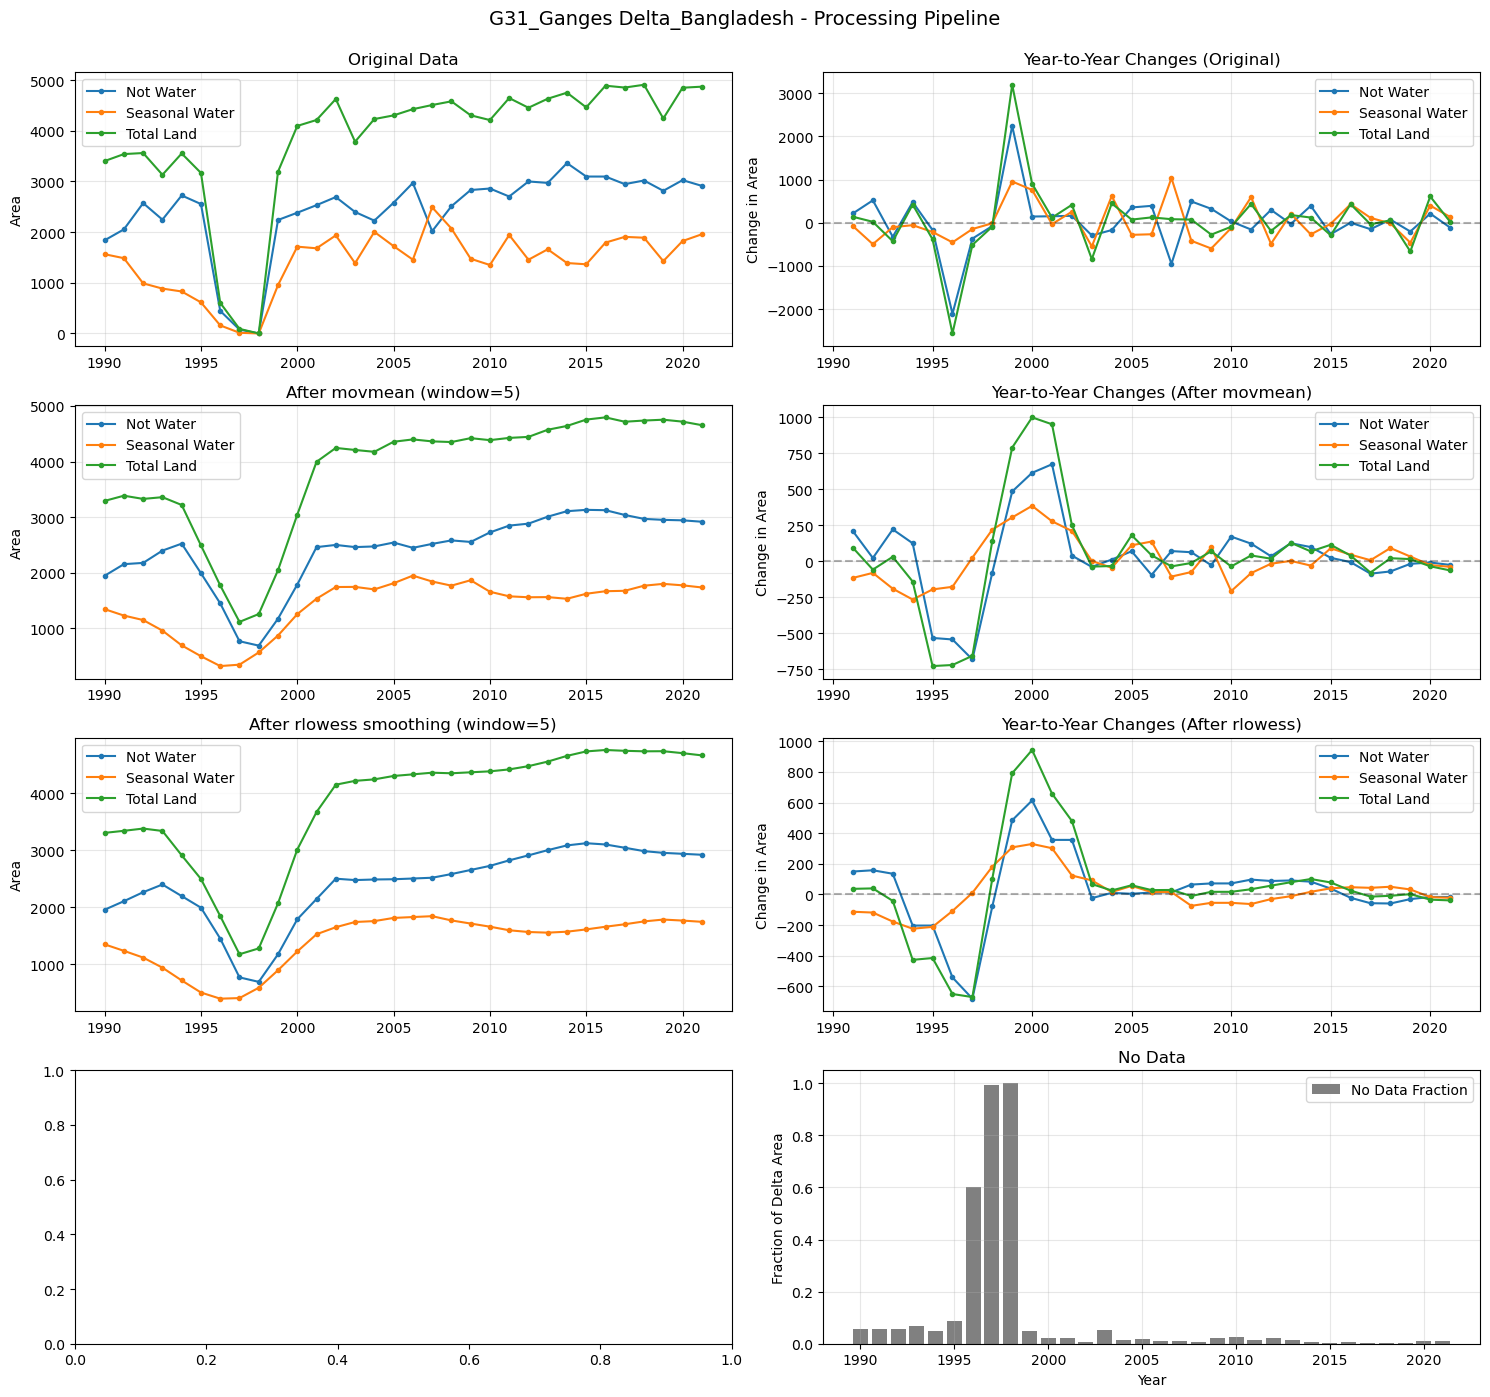

In [209]:
# Filter data from 1990 onwards
notwater_df_1990 = notwater_df[notwater_df.index >= 1990]
seasonal_water_df_1990 = seasonal_water_df[seasonal_water_df.index >= 1990]
water_df_1990 = water_df[water_df.index >= 1990]
nodata_df_1990 = nodata_df[nodata_df.index >= 1990]
nodata_fraction_df_1990 = nodata_fraction_df[nodata_fraction_df.index >= 1990]
total_land_df_1990 = total_land_df[total_land_df.index >= 1990]

# Step 1: Apply movmean (rolling mean with window=5, center=True) to fill missing values
# MATLAB equivalent: movmean(data, 5)
notwater_movmean = notwater_df_1990.rolling(window=4, center=True, min_periods=1).mean()
seasonal_water_movmean = seasonal_water_df_1990.rolling(window=5, center=True, min_periods=1).mean()
total_land_movmean = notwater_movmean + seasonal_water_movmean

# Step 2: Apply rlowess (Robust Locally Weighted Scatterplot Smoothing)
# MATLAB equivalent: smoothdata(data, 'rlowess', 5)
from statsmodels.nonparametric.smoothers_lowess import lowess

def apply_rlowess(df, window=5):
    """Apply robust LOWESS smoothing"""
    df_smoothed = df.copy()
    n = len(df)
    # frac is the fraction of data used for smoothing
    # For window=5, frac ≈ 5/n, but typically we want a bit more data
    frac = max(window / n, 0.1)  # At least 10% of data
    
    for col in df.columns:
        # lowess returns (x, smoothed_y), we take the smoothed values
        smoothed = lowess(df[col].values, df.index.values, frac=frac, return_sorted=False)
        df_smoothed[col] = smoothed
    
    return df_smoothed

notwater_smooth = apply_rlowess(notwater_movmean, window=5)
seasonal_water_smooth = apply_rlowess(seasonal_water_movmean, window=5)
total_land_smooth = notwater_smooth + seasonal_water_smooth

# Calculate year-to-year differences
notwater_diff = notwater_df_1990.diff()
seasonal_water_diff = seasonal_water_df_1990.diff()
total_land_diff = total_land_df_1990.diff()
nodata_diff = nodata_df_1990.diff()
nodata_fraction_diff = nodata_fraction_df_1990.diff()

notwater_diff_movmean = notwater_movmean.diff()
seasonal_water_diff_movmean = seasonal_water_movmean.diff()
total_land_diff_movmean = total_land_movmean.diff()

notwater_diff_smooth = notwater_smooth.diff()
seasonal_water_diff_smooth = seasonal_water_smooth.diff()
total_land_diff_smooth = total_land_smooth.diff()

# Plot timeseries for G31_Ganges Delta_Bangladesh
delta_name = 'G31_Ganges Delta_Bangladesh'

fig, axes = plt.subplots(4, 2, figsize=(15, 14))

# Column 1: Original values
axes[0, 0].plot(notwater_df_1990.index, notwater_df_1990[delta_name], label='Not Water', marker='o', markersize=3)
axes[0, 0].plot(seasonal_water_df_1990.index, seasonal_water_df_1990[delta_name], label='Seasonal Water', marker='o', markersize=3)
axes[0, 0].plot(total_land_df_1990.index, total_land_df_1990[delta_name], label='Total Land', marker='o', markersize=3)
axes[0, 0].set_ylabel('Area')
axes[0, 0].set_title('Original Data')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[1, 0].plot(notwater_movmean.index, notwater_movmean[delta_name], label='Not Water', marker='o', markersize=3)
axes[1, 0].plot(seasonal_water_movmean.index, seasonal_water_movmean[delta_name], label='Seasonal Water', marker='o', markersize=3)
axes[1, 0].plot(total_land_movmean.index, total_land_movmean[delta_name], label='Total Land', marker='o', markersize=3)
axes[1, 0].set_ylabel('Area')
axes[1, 0].set_title('After movmean (window=5)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[2, 0].plot(notwater_smooth.index, notwater_smooth[delta_name], label='Not Water', marker='o', markersize=3)
axes[2, 0].plot(seasonal_water_smooth.index, seasonal_water_smooth[delta_name], label='Seasonal Water', marker='o', markersize=3)
axes[2, 0].plot(total_land_smooth.index, total_land_smooth[delta_name], label='Total Land', marker='o', markersize=3)
axes[2, 0].set_ylabel('Area')
axes[2, 0].set_title('After rlowess smoothing (window=5)')
axes[2, 0].legend()
axes[2, 0].grid(True, alpha=0.3)



# Column 2: Year-to-year changes
axes[0, 1].plot(notwater_diff.index, notwater_diff[delta_name], label='Not Water', marker='o', markersize=3)
axes[0, 1].plot(seasonal_water_diff.index, seasonal_water_diff[delta_name], label='Seasonal Water', marker='o', markersize=3)
axes[0, 1].plot(total_land_diff.index, total_land_diff[delta_name], label='Total Land', marker='o', markersize=3)
axes[0, 1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[0, 1].set_ylabel('Change in Area')
axes[0, 1].set_title('Year-to-Year Changes (Original)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 1].plot(notwater_diff_movmean.index, notwater_diff_movmean[delta_name], label='Not Water', marker='o', markersize=3)
axes[1, 1].plot(seasonal_water_diff_movmean.index, seasonal_water_diff_movmean[delta_name], label='Seasonal Water', marker='o', markersize=3)
axes[1, 1].plot(total_land_diff_movmean.index, total_land_diff_movmean[delta_name], label='Total Land', marker='o', markersize=3)
axes[1, 1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1, 1].set_ylabel('Change in Area')
axes[1, 1].set_title('Year-to-Year Changes (After movmean)')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

axes[2, 1].plot(notwater_diff_smooth.index, notwater_diff_smooth[delta_name], label='Not Water', marker='o', markersize=3)
axes[2, 1].plot(seasonal_water_diff_smooth.index, seasonal_water_diff_smooth[delta_name], label='Seasonal Water', marker='o', markersize=3)
axes[2, 1].plot(total_land_diff_smooth.index, total_land_diff_smooth[delta_name], label='Total Land', marker='o', markersize=3)
axes[2, 1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[2, 1].set_ylabel('Change in Area')
axes[2, 1].set_title('Year-to-Year Changes (After rlowess)')
axes[2, 1].legend()
axes[2, 1].grid(True, alpha=0.3)

axes[3, 1].bar(nodata_fraction_df_1990.index, nodata_fraction_df_1990[delta_name], label='No Data Fraction',  color='gray')
axes[3, 1].set_xlabel('Year')
axes[3, 1].set_ylabel('Fraction of Delta Area')
axes[3, 1].set_title('No Data')
axes[3, 1].legend()
axes[3, 1].grid(True, alpha=0.3)

fig.suptitle(f'{delta_name} - Processing Pipeline', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

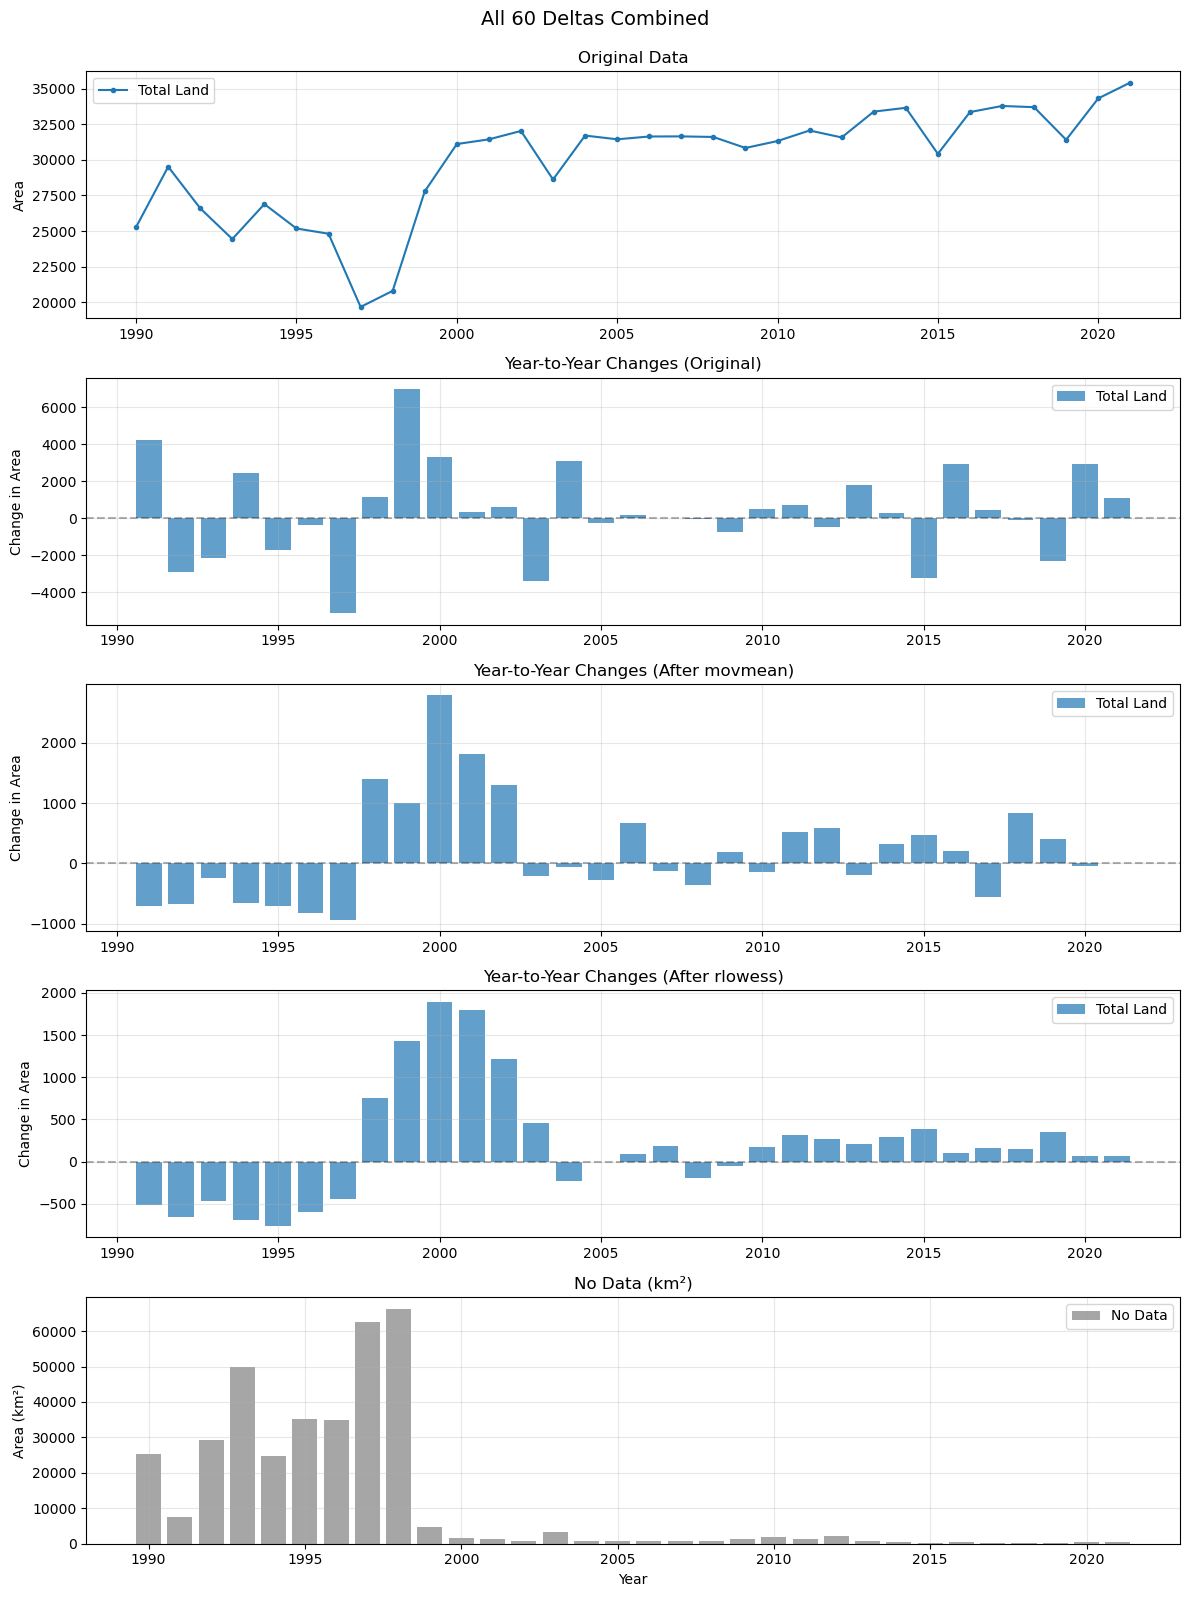

In [197]:
# Sum across all deltas
total_land_all = total_land_df_1990.sum(axis=1)
total_land_movmean_all = total_land_movmean.sum(axis=1)
total_land_smooth_all = total_land_smooth.sum(axis=1)
nodata_all = nodata_df_1990.sum(axis=1)  # Use sum for km² in combined plots

# Calculate year-to-year differences for all deltas combined
total_land_diff_all = total_land_all.diff()
total_land_diff_movmean_all = total_land_movmean_all.diff()
total_land_diff_smooth_all = total_land_smooth_all.diff()

# Plot combined data for all deltas
fig, axes = plt.subplots(5, 1, figsize=(12, 16))

# Original values
axes[0].plot(total_land_all.index, total_land_all, label='Total Land', marker='o', markersize=3)
axes[0].set_ylabel('Area')
axes[0].set_title('Original Data')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Year-to-year changes - Original (bars)
axes[1].bar(total_land_diff_all.index, total_land_diff_all, label='Total Land', alpha=0.7)
axes[1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1].set_ylabel('Change in Area')
axes[1].set_title('Year-to-Year Changes (Original)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Year-to-year changes - After movmean (bars)
axes[2].bar(total_land_diff_movmean_all.index, total_land_diff_movmean_all, label='Total Land', alpha=0.7)
axes[2].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[2].set_ylabel('Change in Area')
axes[2].set_title('Year-to-Year Changes (After movmean)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

# Year-to-year changes - After rlowess (bars)
axes[3].bar(total_land_diff_smooth_all.index, total_land_diff_smooth_all, label='Total Land', alpha=0.7)
axes[3].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[3].set_ylabel('Change in Area')
axes[3].set_title('Year-to-Year Changes (After rlowess)')
axes[3].legend()
axes[3].grid(True, alpha=0.3)

# No Data in km² (bars)
axes[4].bar(nodata_all.index, nodata_all, label='No Data', alpha=0.7, color='gray')
axes[4].set_xlabel('Year')
axes[4].set_ylabel('Area (km²)')
axes[4].set_title('No Data (km²)')
axes[4].legend()
axes[4].grid(True, alpha=0.3)

fig.suptitle('All 60 Deltas Combined', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

In [222]:
# Analyze nodata fraction: count years exceeding thresholds for each delta
threshold_01 = 0.1
threshold_05 = 0.5

# Count years exceeding thresholds for each delta
years_above_01 = (nodata_fraction_df_1990 > threshold_01).sum(axis=0)
years_above_05 = (nodata_fraction_df_1990 > threshold_05).sum(axis=0)

# Create summary dataframe
nodata_analysis = pd.DataFrame({
    'Delta': years_above_01.index,
    'Years_above_0.1': years_above_01.values,
    'Years_above_0.5': years_above_05.values,
    'Total_years': len(nodata_fraction_df_1990)
})

# Calculate percentages
nodata_analysis['Percent_above_0.1'] = (nodata_analysis['Years_above_0.1'] / nodata_analysis['Total_years'] * 100).round(1)
nodata_analysis['Percent_above_0.5'] = (nodata_analysis['Years_above_0.5'] / nodata_analysis['Total_years'] * 100).round(1)

# Sort by years above 0.1 (most compromised first)
nodata_analysis = nodata_analysis.sort_values('Years_above_0.1', ascending=False)

# Display summary statistics
print("="*80)
print("NODATA FRACTION ANALYSIS SUMMARY")
print("="*80)
print(f"\nTotal deltas analyzed: {len(nodata_analysis)}")
print(f"Years analyzed: {len(nodata_fraction_df_1990)} (1990-2021)")
print(f"\n--- Threshold > 0.1 (>10% no data) ---")
print(f"Deltas affected: {(nodata_analysis['Years_above_0.1'] > 0).sum()}")

print(f"\n--- Threshold > 0.5 (>50% no data) ---")
print(f"Deltas affected: {(nodata_analysis['Years_above_0.5'] > 0).sum()}")

print(f"\n--- Top 10 most compromised deltas (by >0.1 threshold) ---")
print(nodata_analysis.head(10).to_string(index=False))

# Save to CSV
nodata_analysis.to_csv('nodata_fraction_analysis.csv', index=False)
print("\nFull analysis saved to 'nodata_fraction_analysis.csv'")
print("="*80)

NODATA FRACTION ANALYSIS SUMMARY

Total deltas analyzed: 60
Years analyzed: 32 (1990-2021)

--- Threshold > 0.1 (>10% no data) ---
Deltas affected: 33

--- Threshold > 0.5 (>50% no data) ---
Deltas affected: 27

--- Top 10 most compromised deltas (by >0.1 threshold) ---
                         Delta  Years_above_0.1  Years_above_0.5  Total_years  Percent_above_0.1  Percent_above_0.5
      G40_Mekong Delta_Vietnam                9                6           32               28.1               18.8
    MX43_Rajang Delta_Malaysia                7                1           32               21.9                3.1
      G69_Danube Delta_Rumania                6                3           32               18.8                9.4
      G04_Zhujiang Delta_China                6                2           32               18.8                6.2
   G25_Irrawaddy Delta_Myanmar                6                5           32               18.8               15.6
    G10_Thanlyin Delta_Myanmar   

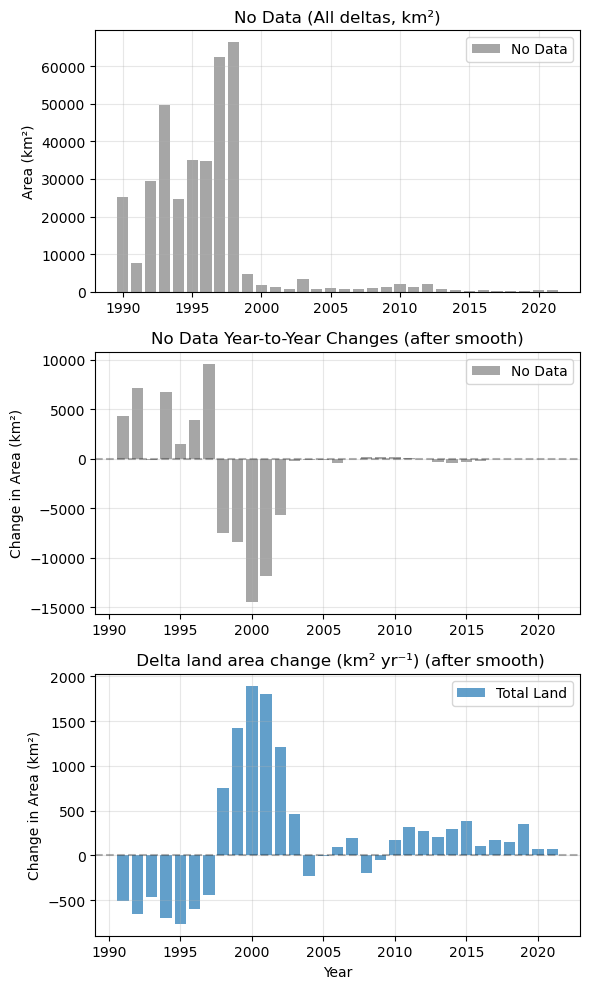

In [220]:
# Apply same smoothing to nodata in km²
nodata_movmean = nodata_df_1990.rolling(window=4, center=True, min_periods=1).mean()
nodata_smooth = apply_rlowess(nodata_movmean, window=5)

# Sum across all deltas for nodata in km²
nodata_movmean_all = nodata_movmean.sum(axis=1)
nodata_smooth_all = nodata_smooth.sum(axis=1)

# Calculate year-to-year differences for smoothed nodata
nodata_diff_smooth_all = nodata_smooth_all.diff()

# Create a separate plot with No Data in km² original and smoothed No Data changes
fig, axes = plt.subplots(3, 1, figsize=(6, 10))

# No Data km² original values (bars)
axes[0].bar(nodata_all.index, nodata_all, label='No Data', alpha=0.7, color='gray')
axes[0].set_ylabel('Area (km²)')
axes[0].set_title('No Data (All deltas, km²)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Year-to-year changes - No Data After rlowess (bars)
axes[1].bar(nodata_diff_smooth_all.index, nodata_diff_smooth_all, label='No Data', alpha=0.7, color='gray')
axes[1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1].set_ylabel('Change in Area (km²)')
axes[1].set_title('No Data Year-to-Year Changes (after smooth)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Year-to-year changes - Total Land After rlowess (bars)
axes[2].bar(total_land_diff_smooth_all.index, total_land_diff_smooth_all, label='Total Land', alpha=0.7)
axes[2].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Change in Area (km²)')
axes[2].set_title(' Delta land area change (km² yr⁻¹) (after smooth)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

#fig.suptitle('All 60 Deltas Combined - No Data vs Total Land Analysis', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

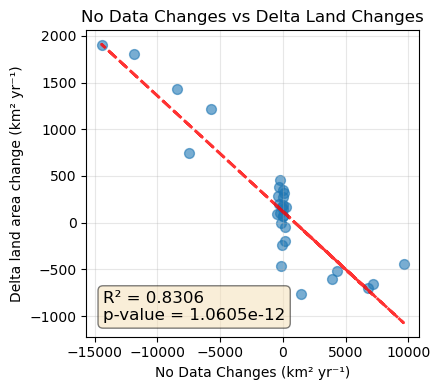

In [217]:
# Correlation between nodata (km²) year-to-year changes and total land year-to-year changes
from scipy.stats import pearsonr

# Remove NaN values for correlation calculation
mask = ~(nodata_diff_smooth_all.isna() | total_land_diff_smooth_all.isna())
x = nodata_diff_smooth_all[mask]
y = total_land_diff_smooth_all[mask]

# Calculate correlation
r, p_value = pearsonr(x, y)
r2 = r**2

# Create scatter plot
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(x, y, alpha=0.6, s=50)

# Add trend line
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
ax.plot(x, p(x), "r--", alpha=0.8, linewidth=2)

# Add R² to plot
ax.text(0.05, 0.15, f'R² = {r2:.4f}\np-value = {p_value:.4e}', 
        transform=ax.transAxes, fontsize=12, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax.set_xlabel('No Data Changes (km² yr⁻¹)')
ax.set_ylabel('Delta land area change (km² yr⁻¹)')
ax.set_title('No Data Changes vs Delta Land Changes')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

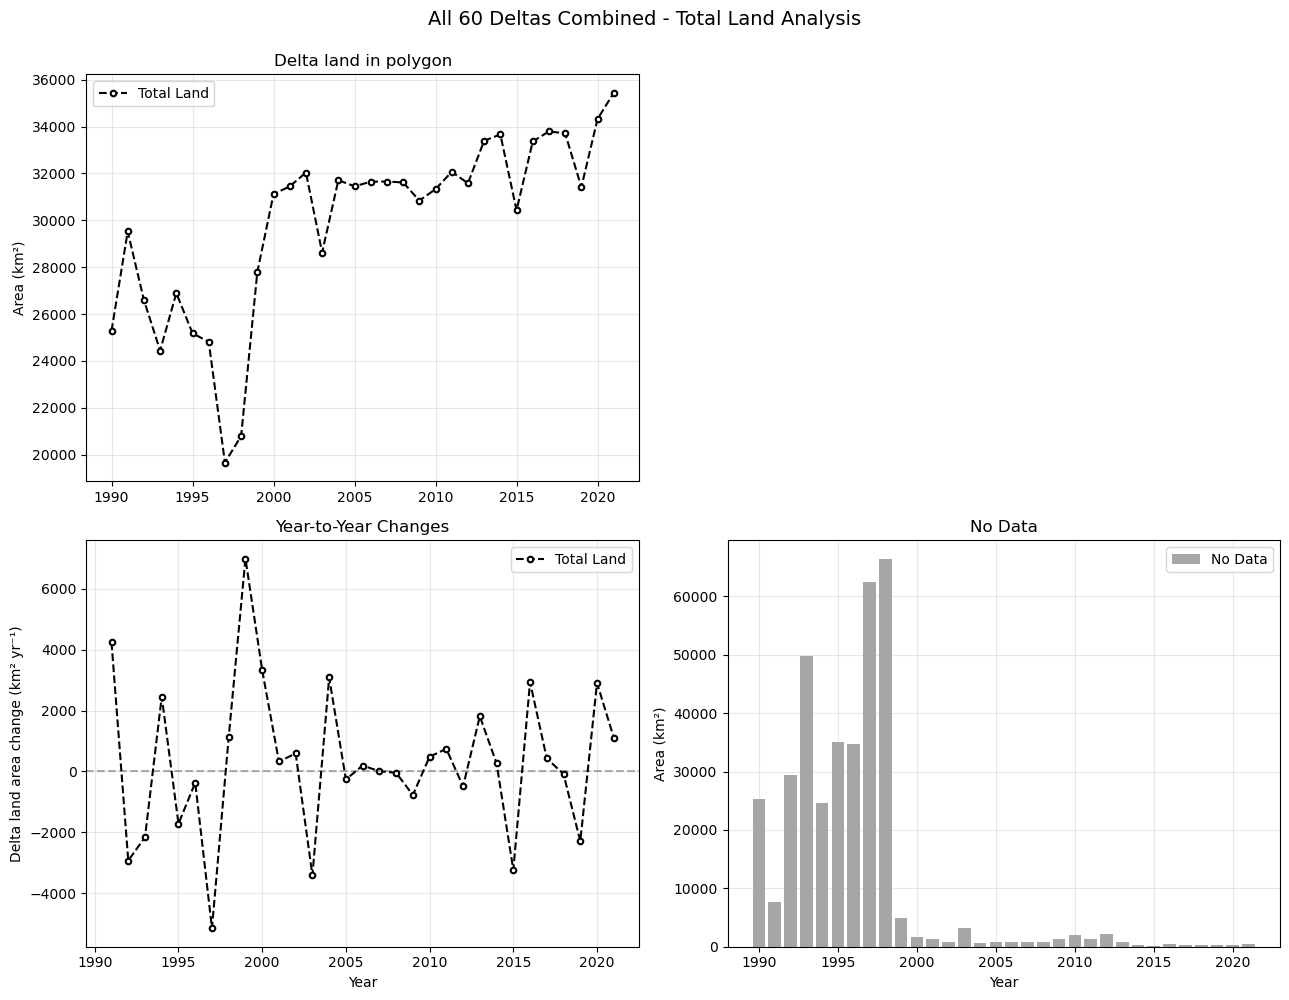

In [ ]:
# Create 2x2 subplot with Total Land and No Data (km²)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Top left: Original Total Land data
axes[0, 0].plot(total_land_all.index, total_land_all, label='Total Land', marker='o', markersize=4, 
                linestyle='--', color='black', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
axes[0, 0].set_ylabel('Area (km²)')
axes[0, 0].set_title('Delta land in polygon')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Top right: Empty subplot
axes[0, 1].axis('off')

# Bottom left: Year-to-year changes (original)
axes[1, 0].plot(total_land_diff_all.index, total_land_diff_all, label='Total Land', marker='o', markersize=4, 
                linestyle='--', color='black', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
axes[1, 0].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_ylabel('Delta land area change (km² yr⁻¹)')
axes[1, 0].set_title('Year-to-Year Changes')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Bottom right: No Data in km²
axes[1, 1].bar(nodata_all.index, nodata_all, label='No Data', alpha=0.7, color='gray')
axes[1, 1].set_xlabel('Year')
axes[1, 1].set_ylabel('Area (km²)')
axes[1, 1].set_title('No Data')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

fig.suptitle('All 60 Deltas Combined - Total Land Analysis', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

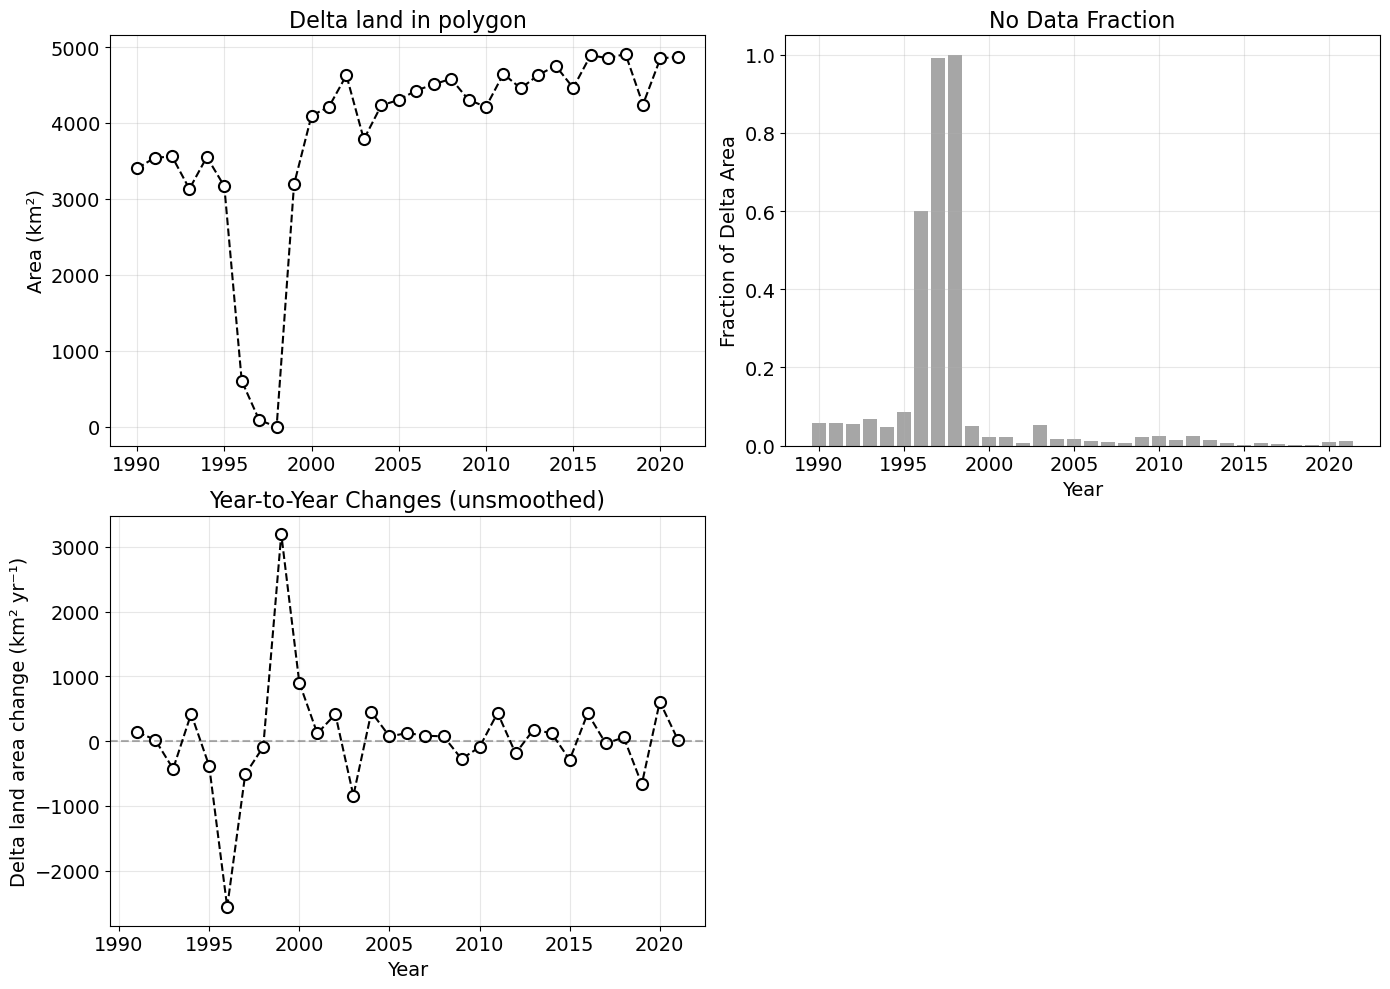

In [236]:
# Create 2x2 subplot for Ganges Delta specifically
delta_name = 'G31_Ganges Delta_Bangladesh'

# Extract data for Ganges Delta
ganges_total_land = total_land_df_1990[delta_name]
ganges_total_land_diff = total_land_diff[delta_name]
ganges_nodata_fraction = nodata_fraction_df_1990[delta_name]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top left: Ganges Delta land data
axes[0, 0].plot(ganges_total_land.index, ganges_total_land, label='Total Land', marker='o', markersize=8, 
                linestyle='--', color='black', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
axes[0, 0].set_ylabel('Area (km²)', fontsize=14)
axes[0, 0].set_title('Delta land in polygon', fontsize=16)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].tick_params(axis='both', labelsize=14)

# Top right: Empty subplot
axes[1, 1].axis('off')

# Bottom left: Year-to-year changes for Ganges
axes[1, 0].plot(ganges_total_land_diff.index, ganges_total_land_diff, label='Total Land', marker='o', markersize=8, 
                linestyle='--', color='black', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
axes[1, 0].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1, 0].set_xlabel('Year', fontsize=14)
axes[1, 0].set_ylabel('Delta land area change (km² yr⁻¹)', fontsize=14)
axes[1, 0].set_title('Year-to-Year Changes (unsmoothed)', fontsize=16)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].tick_params(axis='both', labelsize=14)

# Bottom right: No Data fraction for Ganges
axes[0, 1].bar(ganges_nodata_fraction.index, ganges_nodata_fraction, label='No Data Fraction', alpha=0.7, color='gray')
axes[0, 1].set_xlabel('Year', fontsize=14)
axes[0, 1].set_ylabel('Fraction of Delta Area', fontsize=14)
axes[0, 1].set_title('No Data Fraction', fontsize=16)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.show()